<div dir="rtl">

# کارگاه جلسه ۲۶ — مبانی خوشه‌بندی و k-Means

این دفترچه ابزارهایی را نشان می‌دهد که در جزوه نیامده‌اند و تمرین عملی کلاس را با پاسخ دارد. نوشتن این کدها در امتحان پرسیده نمی‌شود.

## ۱. نسخه دسته‌کوچک برای داده بزرگ

کلاس `MiniBatchKMeans` در هر گام فقط یک زیرنمونه کوچک (مثلاً ۲۰۴۸ نقطه) را برای به‌روزرسانی مراکز به کار می‌برد. روی ۲۰۰ هزار نقطه زمان و SSE آن را با `KMeans` مقایسه می‌کنیم.

</div>

In [1]:
import time
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans, MiniBatchKMeans

X_big, _ = make_blobs(n_samples=200_000, centers=5, n_features=4, random_state=42)
for model in [KMeans(5, n_init=3, random_state=42),
              MiniBatchKMeans(5, batch_size=2048, n_init=3, random_state=42)]:
    t0 = time.perf_counter()
    model.fit(X_big)
    print(f"{type(model).__name__:16s} time={time.perf_counter() - t0:.2f}s  SSE={model.inertia_:,.0f}")

KMeans           time=0.11s  SSE=800,706
MiniBatchKMeans  time=0.03s  SSE=800,834


<div dir="rtl">

نسخه دسته‌کوچک معمولاً چند برابر سریع‌تر است و SSE آن کمی بیشتر؛ برای میلیون‌ها نقطه یا داده جریانی (با `partial_fit`) مناسب است.

## ۲. نسبت دادن مشتری جدید به خوشه‌ها

مدل k-Means پس از آموزش، مشتری جدید را با `predict` به نزدیک‌ترین مرکز نسبت می‌دهد و `transform` فاصله او را تا همه مراکز (در فضای استانداردشده) برمی‌گرداند.

</div>

In [2]:
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

path = "../data/Mall_Customers.csv"
mall = pd.read_csv(path)
cols = ["Annual Income (k$)", "Spending Score (1-100)"]
model = make_pipeline(StandardScaler(), KMeans(n_clusters=5, n_init=10, random_state=42)).fit(mall[cols])

new = pd.DataFrame([[30, 85], [90, 15], [60, 50]], columns=cols)
print(new.assign(cluster=model.predict(new)))
print(pd.DataFrame(model.transform(new).round(2), columns=[f"dist_{j}" for j in range(5)]))

   Annual Income (k$)  Spending Score (1-100)  cluster
0                  30                      85        2
1                  90                      15        3
2                  60                      50        0
   dist_0  dist_1  dist_2  dist_3  dist_4
0    1.68    2.16    0.27    3.45    2.49
1    1.88    2.61    3.50    0.11    2.44
2    0.18    1.61    1.74    1.67    1.71


<div dir="rtl">

## ۳. (اختیاری) الگوریتم k-Medoids

کلاس `KMedoids` در کتابخانه جداگانه scikit-learn-extra است و ممکن است با نسخه‌های جدید numpy نصب نشود:

```python
# pip install scikit-learn-extra
# from sklearn_extra.cluster import KMedoids
# km = KMedoids(n_clusters=5, metric="manhattan", method="pam", random_state=42).fit(Xs)
# km.medoid_indices_   # row numbers of the real customers chosen as medoids
```

## تمرین عملی کلاس (۲۵ دقیقه): خوشه‌بندی مشتریان با سن و امتیاز خرید

با همان داده Mall Customers این بار فقط دو ویژگی **سن** و **امتیاز خرید** را به کار ببرید.

1. نمودار پراکندگی دو ویژگی را رسم کنید. چند گروه به چشم می‌آید؟
2. ویژگی‌ها را استاندارد کنید و برای k از ۲ تا ۸، SSE و میانگین ضریب نیم‌رخ را (با `n_init=10` و `random_state=42`) جدول و نمودار کنید.
3. چه kای پیشنهاد می‌کنید؟ آیا آرنج و نیم‌رخ هم‌نظرند؟
4. با k منتخب، خوشه‌ها را با مراکز رسم کنید و نیم‌رخ هر خوشه (میانگین سن، امتیاز خرید و **درآمد**، و تعداد) را بسازید و برای هر خوشه نامی پیشنهاد دهید.
5. مشتری ۲۸ ساله با امتیاز خرید ۷۰ و مشتری ۶۰ ساله با امتیاز ۳۰ در کدام خوشه‌اند؟

</div>

In [3]:
# Write your solution here

<div dir="rtl">

### پاسخ تمرین

</div>

k                 2        3       4       5       6       7       8
SSE         189.387  124.326  89.765  71.296  53.128  45.907  39.185
silhouette    0.472    0.440   0.438   0.448   0.457   0.411   0.405
          Age  Spending Score (1-100)  Annual Income (k$)  size
cluster                                                        
0        27.2                    40.0                59.6    50
1        30.3                    79.8                63.8    65
2        47.6                    15.0                63.8    38
3        56.0                    48.5                54.4    47


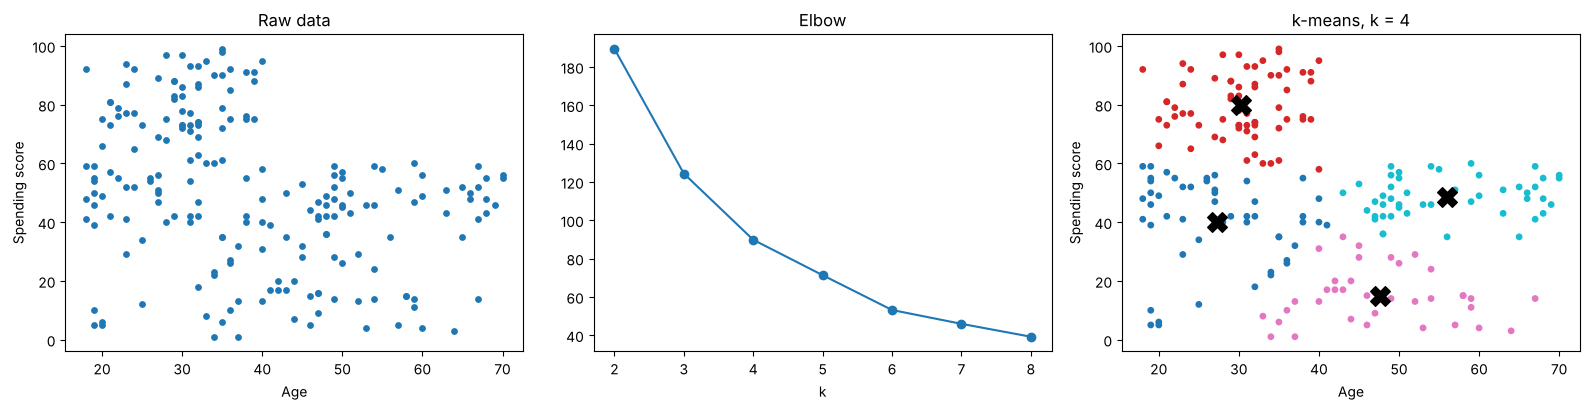

   Age  Spending Score (1-100)  cluster
0   28                      70        1
1   60                      30        3


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

path = "../data/Mall_Customers.csv"
mall = pd.read_csv(path)
cols = ["Age", "Spending Score (1-100)"]

# 2. SSE and silhouette for k = 2..8
Xs = StandardScaler().fit_transform(mall[cols])
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    rows.append({"k": k, "SSE": km.inertia_, "silhouette": silhouette_score(Xs, km.labels_)})
res = pd.DataFrame(rows).set_index("k")
print(res.round(3).T.to_string())

# 4. Chosen k, profile and picture
k = 4
model = make_pipeline(StandardScaler(), KMeans(n_clusters=k, n_init=10, random_state=42)).fit(mall[cols])
mall["cluster"] = model[-1].labels_
profile = mall.groupby("cluster")[cols + ["Annual Income (k$)"]].mean().round(1)
profile["size"] = mall["cluster"].value_counts().sort_index()
print(profile.sort_values("Age"))

centres = model[0].inverse_transform(model[-1].cluster_centers_)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].scatter(mall[cols[0]], mall[cols[1]], s=15)
axes[0].set(xlabel="Age", ylabel="Spending score", title="Raw data")
axes[1].plot(res.index, res["SSE"], "o-", label="SSE")
axes[1].set(xlabel="k", title="Elbow")
axes[2].scatter(mall[cols[0]], mall[cols[1]], c=mall["cluster"], cmap="tab10", s=15)
axes[2].scatter(centres[:, 0], centres[:, 1], c="black", marker="X", s=200)
axes[2].set(xlabel="Age", ylabel="Spending score", title=f"k-means, k = {k}")
plt.tight_layout()
plt.show()

# 5. Two new customers
new = pd.DataFrame([[28, 70], [60, 30]], columns=cols)
print(new.assign(cluster=model.predict(new)))

<div dir="rtl">

### پاسخ‌های کلیدی

- در نمودار پراکندگی مرز روشنی دیده نمی‌شود؛ فقط پیداست که مشتریان بالای حدود ۴۰ سال امتیاز خرید بالای ۶۰ ندارند.
- ضریب نیم‌رخ بیشینه را در k برابر **۲** می‌دهد (۰.۴۷۲) و بقیه مقادیر تا k برابر ۶ نزدیک به هم‌اند (۰.۴۴ تا ۰.۴۶). منحنی SSE هموار است و آرنج مشخصی ندارد (شاید ۴). برخلاف داده درآمد و امتیاز خرید، این دو روش هم‌نظر نیستند؛ نمونه‌ای واقعی از ابهام انتخاب k.
- دو خوشه برای بازاریابی بیش از حد کلی است؛ k برابر **۴** با نیم‌رخ ۰.۴۳۸ تقریباً همان کیفیت را دارد و تفسیرپذیرتر است:

| خوشه | سن | امتیاز خرید | درآمد | تعداد | نام پیشنهادی |
|:---:|:---:|:---:|:---:|:---:|:---:|
| ۰ | ۲۷ | ۴۰ | ۶۰ | 50 | جوانان میانه‌رو |
| ۱ | ۳۰ | ۸۰ | ۶۴ | 65 | جوانان پرخرج |
| ۲ | ۴۸ | ۱۵ | ۶۴ | 38 | میانسالان کم‌خرج |
| ۳ | ۵۶ | ۴۹ | ۵۴ | 47 | مسن‌ترهای میانه‌رو |

- میانگین درآمد در چهار خوشه تقریباً یکسان است (۵۴ تا ۶۴)؛ یعنی سن و امتیاز خرید اطلاعاتی درباره درآمد نمی‌دهند و برای کمپین پردرآمدها باید خوشه‌بندی جلسه را به کار برد.
- مشتری ۲۸ ساله با امتیاز ۷۰ در خوشه ۱ (جوانان پرخرج) و مشتری ۶۰ ساله با امتیاز ۳۰ در خوشه ۳ (مسن‌ترهای میانه‌رو) قرار می‌گیرد.

</div>